# Etapa 5 — Redes Bayesianas: Dependências Meteorológicas, Inferência por Enumeração e d-Separação

**Pergunta central:** Como estruturar de forma compacta e interpretável as dependências entre regime sazonal ($M$), precipitação instantânea ($R$), estiagem acumulada ($S$), horário de detecção ($H$) e potência radiativa elevada ($F$) em focos já detectados no bioma Amazônia, e como responder a consultas causais, diagnósticas e intercausais por inferência exata?

Na Etapa 3 observamos que os atributos meteorológicos violam fortemente a hipótese de independência condicional dada a classe ($S$ e $R$ apresentaram $\phi \approx -0{,}328$ quando $F=1$), o que faz o Naive Bayes da Etapa 4 contar evidências redundantes duas vezes. Nesta etapa (Seção 8 da especificação), modelamos explicitamente essas relações por meio de uma **Rede Bayesiana** (Grafo Acíclico Dirigido — DAG) sobre cinco variáveis binárias:

| Símbolo | Variável no dataset | Evento (valor 1) | Regra de corte (aprendida só no treino) | Papel na rede |
|---|---|---|---|---|
| $M$ | `mes` | Mês $\ge$ corte (setembro a dezembro) | Mediana de `mes` no treino ($9{,}0$) | Raiz sazonal |
| $R$ | `precipitacao` | Chuva no instante da detecção ($> 0$ mm) | Mediana no treino ($0{,}0$ mm, desigualdade estrita) | Condição atmosférica imediata |
| $S$ | `numero_dias_sem_chuva` | Período longo sem chuva ($\ge$ corte) | Mediana no treino ($10$ a $11$ dias) | Mediador de estiagem acumulada |
| $H$ | `hora_utc` | Horário UTC $\ge$ corte (final da tarde/noite) | Mediana no treino ($\approx 18{,}1$ h) | Raiz de ciclo diurno / passagem |
| $F$ | `frp` | Potência radiativa elevada ($\text{FRP} \ge Q_{75}$) | Percentil 75 de `frp` no treino ($\approx 58{,}4$ MW) | Alvo / Colisor ($S \to F \leftarrow H$) |

**Protocolo experimental:** Todas as medianas, o limiar $Q_{75}$ de FRP e as Tabelas de Probabilidade Condicional (CPTs) são estimados **exclusivamente no conjunto de treino** (folds espaciais de 2024). O ano de 2025 permanece intocado para a avaliação integrada final.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pgmpy.inference import VariableElimination
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss, log_loss,
)

from aprendizado_probabilistico import BernoulliNaiveBayes
from probabilidade import (
    conjunta, marginal, condicional, phi, informacao_mutua,
    independencia_condicional, contagens_conjuntas,
)
from rede_bayesiana import (
    NOS_PADRAO, ARESTAS_PADRAO, RedeBayesianaBinaria, extrair_variaveis_binarias,
)
from utils import ATRIBUTOS, carregar_dados, iterar_folds, preparar_particao

np.random.seed(42)
pd.set_option("display.max_rows", 100)
pd.set_option("display.precision", 6)
DIRETORIO_GRAFICOS = Path("graficos_etapa5")
DIRETORIO_GRAFICOS.mkdir(exist_ok=True)

/home/hooki/Faculdade/IA/Meio-Ambiente---Equipe-9/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Verificações didáticas — dados sintéticos

Antes de aplicar a rede aos 140.346 registros de 2024, validamos nossa implementação em `rede_bayesiana.py` com um caso sintético de resposta analítica conhecida:
1. Rejeição de grafos cíclicos e ordenação topológica válida;
2. Soma igual a $1$ na distribuição conjunta reconstruída pela rede;
3. Equivalência exata ($|\Delta| < 10^{-12}$) entre `inferencia_por_enumeracao` (do zero) e `VariableElimination` do `pgmpy`;
4. Verificação do efeito de **colisor (*explaining away*)** em $S \to F \leftarrow H$: $S$ e $H$ são marginalmente independentes na rede quando $F$ não é observado, mas tornam-se dependentes assim que observamos $F=1$.

In [2]:
rede_sintetica = RedeBayesianaBinaria()
rede_sintetica.definir_cpts({
    "M": [0.4, 0.6],
    "H": [0.5, 0.5],
    "R": [[0.9, 0.7], [0.1, 0.3]],
    "S": [
        [[0.3, 0.8], [0.1, 0.6]],  # P(S=0 | M, R)
        [[0.7, 0.2], [0.9, 0.4]],  # P(S=1 | M, R)
    ],
    "F": [
        [[0.9, 0.7], [0.6, 0.2]],  # P(F=0 | S, H)
        [[0.1, 0.3], [0.4, 0.8]],  # P(F=1 | S, H)
    ],
})

# 1. Conjunta soma 1
J_sint = rede_sintetica.distribuicao_conjunta_rede()
assert J_sint.shape == (2, 2, 2, 2, 2) and np.isclose(J_sint.sum(), 1.0, atol=1e-12)

# 2. Colisor S -> F <- H fechado sem observar F, aberto ao observar F=1
assert rede_sintetica.d_separados("S", "H", dado=()) is True
assert rede_sintetica.d_separados("S", "H", dado=("F",)) is False
p_s_sem_ev = rede_sintetica.inferencia_por_enumeracao("S")
p_s_dado_h1 = rede_sintetica.inferencia_por_enumeracao("S", {"H": 1})
assert np.allclose(p_s_sem_ev, p_s_dado_h1, atol=1e-12)

p_s_f1_h0 = rede_sintetica.inferencia_por_enumeracao("S", {"F": 1, "H": 0})
p_s_f1_h1 = rede_sintetica.inferencia_por_enumeracao("S", {"F": 1, "H": 1})
assert not np.isclose(p_s_f1_h0[1], p_s_f1_h1[1])

# 3. Igualdade exata com VariableElimination (pgmpy)
ve_sint = VariableElimination(rede_sintetica.para_pgmpy())
for alvo_c, ev_c in [("F", {}), ("F", {"M": 1, "R": 0}), ("S", {"F": 1, "H": 0}), ("M", {"F": 1})]:
    q_enum = rede_sintetica.inferencia_por_enumeracao(alvo_c, ev_c)
    q_pgmpy = ve_sint.query(variables=[alvo_c], evidence=ev_c, show_progress=False).values
    assert np.allclose(q_enum, q_pgmpy, atol=1e-12)

# 4. Rejeição de ciclo
try:
    RedeBayesianaBinaria(nos=("A", "B", "C"), arestas=(("A", "B"), ("B", "C"), ("C", "A")))
except ValueError:
    pass
else:
    raise AssertionError("Grafo com ciclo deveria lançar ValueError.")

print("Verificações sintéticas aprovadas: DAG acíclico, conjunta, d-separação, colisor e igualdade com pgmpy.")

Verificações sintéticas aprovadas: DAG acíclico, conjunta, d-separação, colisor e igualdade com pgmpy.


## 1. Estrutura do DAG e justificativa de cada aresta (Tarefa 1)

O DAG possui **5 nós binários** ($M, R, S, H, F$) e **5 arestas direcionadas**, induzindo a fatoração:

$$P(M, R, S, H, F) = P(M) \cdot P(H) \cdot P(R \mid M) \cdot P(S \mid M, R) \cdot P(F \mid S, H)$$

### Justificativa física e estatística de cada aresta

1. **$M \to R$ (Sazonalidade $\to$ Precipitação no instante da detecção):**
   Na Amazônia, o regime hidrológico varia fortemente ao longo do ano. A transição e o final da estação seca/início da chuvosa ($M=1$, meses 9 a 12) alteram a frequência de eventos convectivos locais no instante em que o foco é registrado pelo satélite. Na triagem da Etapa 3, o par $(R, M)$ apresentou informação mútua condicional relevante ($I(R;M\mid F) = 0{,}0300$ bits, $\phi \approx +0{,}20$).
2. **$M \to S$ (Sazonalidade $\to$ Período longo sem chuva):**
   Mesmo controlando pela chuva instantânea $R$, o mês do ano governa o histórico acumulado de dias consecutivos sem precipitação ($I(S;M\mid F) = 0{,}0544$ bits, $\phi \approx -0{,}27$). Uma chuva isolada ou ausência de chuva no instante do passe não resume toda a memória sazonal da estiagem.
3. **$R \to S$ (Precipitação no instante $\to$ Período longo sem chuva):**
   Esta é a dependência mais forte entre atributos identificada na Etapa 3 ($I(S;R\mid F) = 0{,}0733$ bits, $\phi = -0{,}307$ em $F=0$ e $\phi = -0{,}328$ em $F=1$). Quando há precipitação no momento da detecção ($R=1$), a probabilidade de o pixel acumular 10 ou mais dias sem chuva ($S=1$) cai drasticamente (de $\approx 60\%$ para $\approx 19\%$).
4. **$S \to F$ (Período longo sem chuva $\to$ Potência radiativa elevada):**
   A estiagem prolongada reduz o teor de umidade da serrapilheira e da biomassa combustível, favorecendo uma combustão mais intensa e maior liberação de energia radiativa (FRP $\ge Q_{75}$). Na Etapa 3, vimos que $P(F=1\mid S=1) \approx 30{,}8\%$ contra $P(F=1\mid S=0) \approx 18{,}7\%$.
5. **$H \to F$ (Horário UTC da detecção $\to$ Potência radiativa elevada):**
   O horário da passagem do sensor `AQUA_M-T` reflete o ciclo diurno da umidade relativa do ar, temperatura e vento na superfície, além da geometria de observação orbital, modulando a potência radiativa observada. Na Etapa 3, $H$ mostrou-se praticamente independente de $S$ e $R$ ($I(S;H\mid F) = 0{,}0003$ bits; $I(R;H\mid F) = 0{,}0013$ bits), justificando a ausência de arestas entre $(M, R, S)$ e $H$, e posicionando $F$ como um **colisor** ($S \to F \leftarrow H$).

Nós do DAG: ('M', 'R', 'S', 'H', 'F')
Ordem topológica: ('M', 'H', 'R', 'S', 'F')
Arestas: (('M', 'R'), ('M', 'S'), ('R', 'S'), ('S', 'F'), ('H', 'F'))


,pais Pa(X_i),filhos,ancestrais,descendentes,nº parâmetros livres CPT
nó,,,,,
M,∅ (raiz),"R, S",∅,"F, R, S",1
H,∅ (raiz),F,∅,F,1
R,M,S,M,"F, S",2
S,"M, R",F,"M, R",F,4
F,"S, H",∅ (folha),"H, M, R, S",∅,4


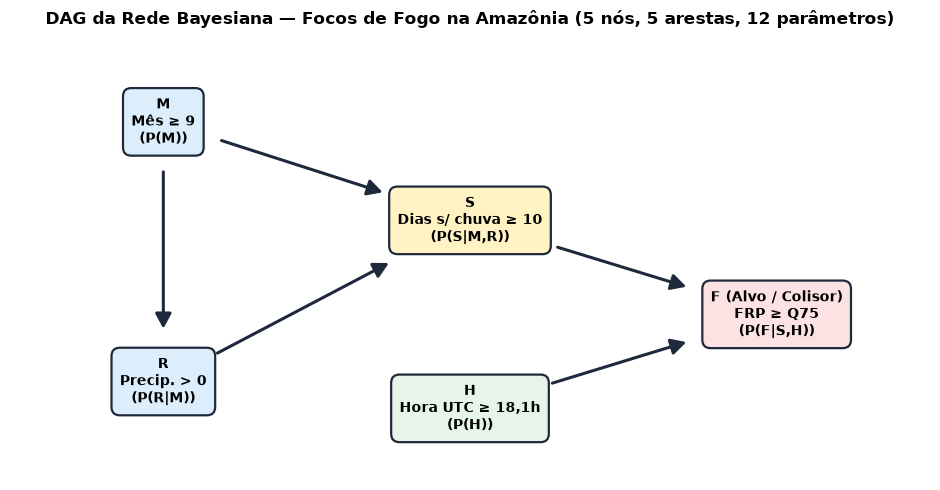

Figura salva em: graficos_etapa5/dag_rede_bayesiana.png


In [3]:
rede_padrao = RedeBayesianaBinaria()
print("Nós do DAG:", rede_padrao.nos)
print("Ordem topológica:", rede_padrao.ordem_topologica)
print("Arestas:", rede_padrao.arestas)

resumo_nos = pd.DataFrame([
    {
        "nó": no,
        "pais Pa(X_i)": ", ".join(rede_padrao.pais[no]) if rede_padrao.pais[no] else "∅ (raiz)",
        "filhos": ", ".join(rede_padrao.filhos[no]) if rede_padrao.filhos[no] else "∅ (folha)",
        "ancestrais": ", ".join(sorted(rede_padrao.ancestrais[no])) or "∅",
        "descendentes": ", ".join(sorted(rede_padrao.descendentes[no])) or "∅",
        "nº parâmetros livres CPT": 2 ** len(rede_padrao.pais[no]),
    }
    for no in rede_padrao.ordem_topologica
]).set_index("nó")
display(resumo_nos)

# Desenho visual do DAG
fig, ax = plt.subplots(figsize=(9.5, 5.0))
posicoes = {
    "M": (0.14, 0.78),
    "R": (0.14, 0.20),
    "S": (0.50, 0.56),
    "H": (0.50, 0.14),
    "F": (0.86, 0.35),
}
descricoes = {
    "M": "M\nMês ≥ 9\n(P(M))",
    "R": "R\nPrecip. > 0\n(P(R|M))",
    "S": "S\nDias s/ chuva ≥ 10\n(P(S|M,R))",
    "H": "H\nHora UTC ≥ 18,1h\n(P(H))",
    "F": "F (Alvo / Colisor)\nFRP ≥ Q75\n(P(F|S,H))",
}
cores = {"M": "#dceefb", "R": "#dceefb", "S": "#fff3c4", "H": "#e6f4ea", "F": "#fde2e4"}
recuos = {
    ("M", "R"): (36, 38),
    ("M", "S"): (44, 66),
    ("R", "S"): (44, 66),
    ("S", "F"): (66, 68),
    ("H", "F"): (62, 68),
}

for u, v in rede_padrao.arestas:
    x1, y1 = posicoes[u]
    x2, y2 = posicoes[v]
    sa, sb = recuos[(u, v)]
    ax.annotate(
        "",
        xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle="-|>,head_length=0.9,head_width=0.48", lw=2.2,
                        color="#1e293b", shrinkA=sa, shrinkB=sb),
        zorder=4,
    )

for no, (x, y) in posicoes.items():
    ax.text(
        x, y, descricoes[no], ha="center", va="center", fontsize=10, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.6", facecolor=cores[no], edgecolor="#1e293b", lw=1.6),
        zorder=2,
    )

ax.set_xlim(-0.04, 1.04)
ax.set_ylim(-0.02, 0.98)
ax.axis("off")
ax.set_title("DAG da Rede Bayesiana — Focos de Fogo na Amazônia (5 nós, 5 arestas, 12 parâmetros)", fontsize=12, fontweight="bold")
fig.tight_layout()
caminho_dag = DIRETORIO_GRAFICOS / "dag_rede_bayesiana.png"
fig.savefig(caminho_dag, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print("Figura salva em:", caminho_dag)

## 2. Economia de parâmetros em relação à conjunta completa (Tarefa 6)

Para $n = 5$ variáveis binárias:
* **Distribuição conjunta completa $P(M, R, S, H, F)$:** possui $2^5 = 32$ eventos atômicos. Como a soma das probabilidades deve ser $1$, são necessários **$2^5 - 1 = 31$ parâmetros livres** (ou $1 + 2 + 4 + 8 + 16 = 31$ parâmetros nas CPTs da regra da cadeia completa sem independências).
* **Rede Bayesiana proposta:** cada nó binário $X_i$ com $k_i = |Pa(X_i)|$ pais binários exige exatamente $2^{k_i}$ parâmetros livres (pois para cada uma das $2^{k_i}$ configurações dos pais basta especificar $P(X_i=1 \mid Pa(X_i))$, sendo $P(X_i=0 \mid Pa(X_i)) = 1 - P(X_i=1 \mid Pa(X_i))$).

In [4]:
econ = rede_padrao.economia_parametros()
tabela_econ = pd.DataFrame([
    {"Componente": f"Nó {no} — P({no} | {','.join(rede_padrao.pais[no])})" if rede_padrao.pais[no] else f"Nó {no} — P({no})",
     "Nº de pais (k)": len(rede_padrao.pais[no]),
     "Configurações dos pais (2^k)": 2 ** len(rede_padrao.pais[no]),
     "Parâmetros livres na Rede": econ["parametros_por_no"][no],
     "Parâmetros na Regra da Cadeia Completa": 2 ** idx}
    for idx, no in enumerate(rede_padrao.ordem_topologica)
])
totais = pd.DataFrame([{
    "Componente": "TOTAL (5 variáveis binárias)",
    "Nº de pais (k)": "—",
    "Configurações dos pais (2^k)": "—",
    "Parâmetros livres na Rede": econ["parametros_rede"],
    "Parâmetros na Regra da Cadeia Completa": econ["parametros_conjunta"],
}])
display(pd.concat([tabela_econ, totais], ignore_index=True))
print(f"Conjunta completa: {econ['parametros_conjunta']} parâmetros livres")
print(f"Rede Bayesiana:    {econ['parametros_rede']} parâmetros livres")
print(f"Economia:          {econ['economia_absoluta']} parâmetros ({econ['economia_relativa']:.1%} de redução)")
assert econ["parametros_conjunta"] == 31 and econ["parametros_rede"] == 12 and econ["economia_absoluta"] == 19

,Componente,Nº de pais (k),Configurações dos pais (2^k),Parâmetros livres na Rede,Parâmetros na Regra da Cadeia Completa
0,Nó M — P(M),0,1,1,1
1,Nó H — P(H),0,1,1,2
2,Nó R — P(R | M),1,2,2,4
3,"Nó S — P(S | M,R)",2,4,4,8
4,"Nó F — P(F | S,H)",2,4,4,16
5,TOTAL (5 variáveis binárias),—,—,12,31


Conjunta completa: 31 parâmetros livres
Rede Bayesiana:    12 parâmetros livres
Economia:          19 parâmetros (61.3% de redução)


## 3. Estimação das CPTs a partir dos dados de 2024 (Tarefa 2)

Carregamos o dataset auditado de desenvolvimento (`2024`) e preparamos o **Fold Espacial 0** ($N_{\text{treino}} = 112.277$, $N_{\text{validação}} = 28.069$). Os cortes são aprendidos apenas no treino do fold e aplicados sem alteração à validação. Em todas as células das CPTs há milhares de observações empíricas, de modo que a estimativa de máxima verossimilhança ($\alpha = 0$) é perfeitamente bem definida e não produz zeros.

In [5]:
dados_2024 = carregar_dados(2024)
fold0, treino0, validacao0 = next(iterar_folds(dados_2024, "espacial"))
particao0 = preparar_particao(treino0, validacao0, "numerica")
med0 = particao0.parametros["medianas"]

V_tr0 = extrair_variaveis_binarias(particao0.X_treino, particao0.y_cls_treino, med0)
V_va0 = extrair_variaveis_binarias(particao0.X_avaliacao, particao0.y_cls_avaliacao, med0)

rede0 = RedeBayesianaBinaria().fit(V_tr0, alpha=0.0)
print(f"Fold espacial {fold0}: N_treino = {rede0.n_treino_:,} | N_validação = {len(validacao0):,} | Limiar FRP (Q75) = {particao0.limiar_frp:.2f} MW")

for no in rede0.ordem_topologica:
    pais_str = f" | {', '.join(rede0.pais[no])}" if rede0.pais[no] else ""
    display(Markdown(f"#### CPT do nó ${no}$: $P({no}{pais_str})$"))
    display(rede0.tabela_cpt(no))

Fold espacial 0: N_treino = 112,277 | N_validação = 28,069 | Limiar FRP (Q75) = 59.50 MW


#### CPT do nó $M$: $P(M)$

,P(M=0),P(M=1),n_treino
marginal,0.473525,0.526475,112277


#### CPT do nó $H$: $P(H)$

,P(H=0),P(H=1),n_treino
marginal,0.481826,0.518174,112277


#### CPT do nó $R$: $P(R | M)$

,P(R=0 | pais),P(R=1 | pais),n_treino
M,,,
0,0.895347,0.104653,53166
1,0.738424,0.261576,59111


#### CPT do nó $S$: $P(S | M, R)$

P(S=0 | pais)  P(S=1 | pais)  n_treino
M R                                        
0 0       0.279022       0.720978     47602
  1       0.760065       0.239935      5564
1 0       0.531467       0.468533     43649
  1       0.825766       0.174234     15462

#### CPT do nó $F$: $P(F | S, H)$

P(F=0 | pais)  P(F=1 | pais)  n_treino
S H                                        
0 0       0.816261       0.183739     25275
  1       0.810439       0.189561     28202
1 0       0.683308       0.316692     28823
  1       0.700203       0.299797     29977

## 4. Inferência por Enumeração do zero e comparação com `pgmpy` (Tarefas 3 e 4)

A inferência por enumeração responde a qualquer consulta $P(X \mid \mathbf{e})$ marginalizando as variáveis ocultas $\mathbf{Y} = \text{Vars} \setminus (\{X\} \cup \mathbf{E})$:

$$P(X \mid \mathbf{e}) = \alpha \sum_{\mathbf{y}} P(X, \mathbf{e}, \mathbf{y}) = \alpha \sum_{\mathbf{y}} \prod_{i=1}^{n} P\big(v_i \mid pa(V_i)\big)$$

Abaixo avaliamos **11 consultas representativas do domínio** (a priori, preditivas/causais diretas e indiretas, diagnósticas e intercausais) no Fold Espacial 0 e comparamos o vetor $[P(X=0\mid\mathbf{e}), P(X=1\mid\mathbf{e})]$ obtido por `inferencia_por_enumeracao` com o `VariableElimination` do `pgmpy`.

In [6]:
modelo_pgmpy0 = rede0.para_pgmpy()
ve0 = VariableElimination(modelo_pgmpy0)

consultas_dominio = [
    ("Priori da classe (sem evidências)", "F", {}),
    ("Causal: seca longa (S=1)", "F", {"S": 1}),
    ("Causal: poucos dias sem chuva (S=0)", "F", {"S": 0}),
    ("Causal: seca longa e horário < 18,1h (S=1, H=0)", "F", {"S": 1, "H": 0}),
    ("Causal: seca longa e horário ≥ 18,1h (S=1, H=1)", "F", {"S": 1, "H": 1}),
    ("Causal indireta: mês ≥ 9 e sem chuva no instante (M=1, R=0)", "F", {"M": 1, "R": 0}),
    ("Causal indireta: mês < 9 e com chuva no instante (M=0, R=1)", "F", {"M": 0, "R": 1}),
    ("Diagnóstica: dado foco de FRP elevada (F=1), prob. de seca longa", "S", {"F": 1}),
    ("Diagnóstica: dado foco de FRP elevada (F=1), prob. de chuva no instante", "R", {"F": 1}),
    ("Intercausal (colisor): dado F=1 e H=0, prob. de seca longa", "S", {"F": 1, "H": 0}),
    ("Intercausal (colisor): dado F=1 e H=1, prob. de seca longa", "S", {"F": 1, "H": 1}),
]

linhas_comp = []
for descricao, var_q, ev in consultas_dominio:
    p_enum = rede0.inferencia_por_enumeracao(var_q, ev)
    p_ve = ve0.query(variables=[var_q], evidence=ev, show_progress=False).values
    erro_abs = float(np.max(np.abs(p_enum - p_ve)))
    ev_str = ", ".join(f"{k}={v}" for k, v in ev.items()) or "∅"
    linhas_comp.append({
        "Consulta": descricao,
        "Expressão": f"P({var_q}=1 | {ev_str})",
        "Enumeração (própria)": float(p_enum[1]),
        "pgmpy (VariableElimination)": float(p_ve[1]),
        "Diferença absoluta máx.": erro_abs,
    })

tabela_comp = pd.DataFrame(linhas_comp)
display(tabela_comp)
max_diff_global = tabela_comp["Diferença absoluta máx."].max()
print(f"Maior diferença absoluta entre Enumeração própria e pgmpy: {max_diff_global:.3e}")
assert max_diff_global < 1e-12

,Consulta,Expressão,Enumeração (própria),pgmpy (VariableElimination),Diferença absoluta máx.
0,Priori da classe (sem evidências),P(F=1 | ∅),0.250219,0.250219,0.000000e+00
1,Causal: seca longa (S=1),P(F=1 | S=1),0.307937,0.307937,1.110223e-16
2,Causal: poucos dias sem chuva (S=0),P(F=1 | S=0),0.186756,0.186756,2.775558e-17
3,"Causal: seca longa e horário < 18,1h (S=1, H=0)","P(F=1 | S=1, H=0)",0.316692,0.316692,1.110223e-16
4,"Causal: seca longa e horário ≥ 18,1h (S=1, H=1)","P(F=1 | S=1, H=1)",0.299797,0.299797,5.551115e-17
5,Causal indireta: mês ≥ 9 e sem chuva no instan...,"P(F=1 | M=1, R=0)",0.243533,0.243533,2.775558e-17
6,Causal indireta: mês < 9 e com chuva no instan...,"P(F=1 | M=0, R=1)",0.215831,0.215831,1.110223e-16
7,"Diagnóstica: dado foco de FRP elevada (F=1), p...",P(S=1 | F=1),0.644508,0.644508,1.110223e-16
8,"Diagnóstica: dado foco de FRP elevada (F=1), p...",P(R=1 | F=1),0.157151,0.157151,0.000000e+00
9,"Intercausal (colisor): dado F=1 e H=0, prob. d...","P(S=1 | F=1, H=0)",0.654596,0.654596,5.551115e-17


Maior diferença absoluta entre Enumeração própria e pgmpy: 1.110e-16


### Propagação de incerteza quando $S$ é variável oculta: $P(F=1 \mid M, R, H)$

Como na nossa Rede Bayesiana os pais diretos de $F$ são $S$ e $H$, e $F$ não possui descendentes, o par $\{S, H\}$ constitui o **Manto de Markov (*Markov Blanket*)** de $F$. Entretanto, quando $S$ **não** é observado (por exemplo, em registros onde `numero_dias_sem_chuva` está ausente antes da imputação, ou em cenários meteorológicos definidos apenas por época do ano $M$, chuva atual $R$ e horário $H$), a rede propaga a incerteza inferindo $P(S \mid M, R)$ e marginalizando $S$:

$$P(F=1 \mid M, R, H) = \sum_{s \in \{0,1\}} P(F=1 \mid S=s, H)\,P(S=s \mid M, R)$$

A tabela abaixo exibe as 8 combinações de $(M, R, H)$ e confirma coincidência exata entre nossa implementação e o `pgmpy`.

In [7]:
linhas_mrh = []
for m_val, r_val, h_val in product((0, 1), repeat=3):
    ev_mrh = {"M": m_val, "R": r_val, "H": h_val}
    p_f_enum = rede0.inferencia_por_enumeracao("F", ev_mrh)[1]
    p_f_ve = ve0.query(variables=["F"], evidence=ev_mrh, show_progress=False).values[1]
    p_s_latente = rede0.inferencia_por_enumeracao("S", {"M": m_val, "R": r_val})[1]
    linhas_mrh.append({
        "M": m_val, "R": r_val, "H": h_val,
        "P(S=1 | M,R) inferida": p_s_latente,
        "P(F=1 | M,R,H) Enumeração": p_f_enum,
        "P(F=1 | M,R,H) pgmpy": p_f_ve,
        "|Δ|": abs(p_f_enum - p_f_ve),
    })
df_mrh = pd.DataFrame(linhas_mrh)
display(df_mrh)
assert (df_mrh["|Δ|"] < 1e-12).all()

,M,R,H,"P(S=1 | M,R) inferida","P(F=1 | M,R,H) Enumeração","P(F=1 | M,R,H) pgmpy",|Δ|
0,0,0,0,0.720978,0.279595,0.279595,0.000000e+00
1,0,0,1,0.720978,0.269038,0.269038,5.551115e-17
2,0,1,0,0.239935,0.215639,0.215639,5.551115e-17
3,0,1,1,0.239935,0.216010,0.216010,2.775558e-17
4,1,0,0,0.468533,0.246032,0.246032,2.775558e-17
5,1,0,1,0.468533,0.241210,0.241210,2.775558e-17
6,1,1,0,0.174234,0.206904,0.206904,2.775558e-17
7,1,1,1,0.174234,0.208768,0.208768,2.775558e-17


## 5. Análise de d-separação e demonstração do Colisor (Tarefa 5 e Gabarito 8.4)

Em um DAG, dois nós $X$ e $Y$ são **d-separados** por um conjunto de evidências $\mathbf{Z}$ ($X \perp_{d} Y \mid \mathbf{Z}$) se e somente se **todos** os caminhos não direcionados entre $X$ e $Y$ estão bloqueados por $\mathbf{Z}$. Uma tripla $A - B - C$ ao longo de um caminho é bloqueada quando:
1. **Cadeia ($A \to B \to C$ ou $A \leftarrow B \leftarrow C$) ou Bifurcação ($A \leftarrow B \to C$):** o mediador/ancestral comum $B$ **está** em $\mathbf{Z}$ (observado).
2. **Colisor ($A \to B \leftarrow C$):** nem o colisor $B$ nem qualquer descendente de $B$ está em $\mathbf{Z}$ (não observado).

### 5.1 Verificação de duas independências condicionais por d-separação

Testamos sistematicamente no nosso DAG:
* **Independência Condicional 1 (Bloqueio de cadeia por $S$):** $M \perp_d F \mid S$ (e também $R \perp_d F \mid S$).
  * Entre $M$ e $F$ existem dois caminhos: $M \to S \to F$ (cadeia centrada em $S$) e $M \to R \to S \to F$ (cadeia passando por $R$ e $S$). Quando $S$ não é observado, ambos estão ativos ($M \not\perp_d F$). Quando **observamos $S$**, a tripla centrada em $S$ bloqueia ambos os caminhos, tornando $M$ e $F$ condicionalmente independentes na rede: $P(F=1 \mid S, M=1) = P(F=1 \mid S, M=0) = P(F=1 \mid S)$.
* **Independência Condicional 2 (Bloqueio por mediador $S$ e colisor $F$ fechado):** $R \perp_d H \mid S$ (e também $S \perp_d H \mid \emptyset$).
  * Todos os caminhos entre os atributos meteorológicos $(M, R, S)$ e o horário $H$ convergem no **colisor** $F$ ($S \to F \leftarrow H$). Enquanto $F$ não é observado, o colisor permanece fechado e bloqueia qualquer dependência entre $(M, R, S)$ e $H$.

In [8]:
pares_teste_dsep = [
    ("Independência 1a (cadeia bloqueada por S)", "M", "F", ("S",)),
    ("Contraste 1a (sem observar S, caminho ativo)", "M", "F", ()),
    ("Independência 1b (cadeia bloqueada por S)", "R", "F", ("S",)),
    ("Independência 2 (colisor F fechado + S observado)", "R", "H", ("S",)),
    ("Colisor fechado (sem observar F)", "S", "H", ()),
    ("Colisor aberto (observando o colisor F)", "S", "H", ("F",)),
    ("Colisor aberto em cadeia (observando F abre R <-> H)", "R", "H", ("F",)),
]

linhas_dsep = []
for rotulo, x_no, y_no, z_conj in pares_teste_dsep:
    relatorio = rede0.analisar_caminhos_d_separacao(x_no, y_no, dado=z_conj)
    d_sep = rede0.d_separados(x_no, y_no, dado=z_conj)
    try:
        d_con_pgmpy = modelo_pgmpy0.is_dconnected(x_no, y_no, observed=list(z_conj))
    except TypeError:
        d_con_pgmpy = modelo_pgmpy0.is_dconnected(x_no, y_no, Z=list(z_conj))
    caminhos_ativos = [" - ".join(r["caminho"]) for r in relatorio if r["ativo"]]

    # Checa numericamente na rede: |P(X=1 | Y=1, Z) - P(X=1 | Y=0, Z)|
    ev_base = {z: 1 for z in z_conj}
    p_x_y1 = rede0.inferencia_por_enumeracao(x_no, {**ev_base, y_no: 1})[1]
    p_x_y0 = rede0.inferencia_por_enumeracao(x_no, {**ev_base, y_no: 0})[1]
    linhas_dsep.append({
        "Cenário": rotulo,
        "Consulta d-sep": f"{x_no} ⊥ {y_no} | {{{', '.join(z_conj)}}}",
        "d-separados (próprio)": d_sep,
        "d-separados (pgmpy)": not d_con_pgmpy,
        "Caminhos ativos": "; ".join(caminhos_ativos) if caminhos_ativos else "Nenhum (todos bloqueados)",
        "|P(X=1|Y=1,Z) - P(X=1|Y=0,Z)| na rede": abs(p_x_y1 - p_x_y0),
    })

df_dsep = pd.DataFrame(linhas_dsep)
display(df_dsep)
assert (df_dsep["d-separados (próprio)"] == df_dsep["d-separados (pgmpy)"]).all()
assert np.allclose(df_dsep.loc[df_dsep["d-separados (próprio)"], "|P(X=1|Y=1,Z) - P(X=1|Y=0,Z)| na rede"], 0.0, atol=1e-12)

,Cenário,Consulta d-sep,d-separados (próprio),d-separados (pgmpy),Caminhos ativos,"|P(X=1|Y=1,Z) - P(X=1|Y=0,Z)| na rede"
0,Independência 1a (cadeia bloqueada por S),M ⊥ F | {S},True,True,Nenhum (todos bloqueados),0.000000e+00
1,"Contraste 1a (sem observar S, caminho ativo)",M ⊥ F | {},False,False,M - R - S - F; M - S - F,4.494031e-02
2,Independência 1b (cadeia bloqueada por S),R ⊥ F | {S},True,True,Nenhum (todos bloqueados),2.775558e-17
3,Independência 2 (colisor F fechado + S observado),R ⊥ H | {S},True,True,Nenhum (todos bloqueados),1.387779e-17
4,Colisor fechado (sem observar F),S ⊥ H | {},True,True,Nenhum (todos bloqueados),0.000000e+00
5,Colisor aberto (observando o colisor F),S ⊥ H | {F},False,False,S - F - H,1.969888e-02
6,Colisor aberto em cadeia (observando F abre R ...,R ⊥ H | {F},False,False,R - M - S - F - H; R - S - F - H,4.911268e-03


### 5.2 Demonstração detalhada do Colisor $S \to F \leftarrow H$: observar $F$ abre o caminho (*Explaining Away*)

Na subestrutura em V ($S \to F \leftarrow H$), a potência radiativa elevada ($F$) é efeito conjunto da estiagem ($S$) e do horário de detecção ($H$):
* **Sem observar $F$ ($\mathbf{Z} = \emptyset$):** o colisor bloqueia o caminho. Saber o horário da passagem ($H=0$ ou $H=1$) não altera em nada a probabilidade inferida de seca prolongada na rede:
  $$P_{\text{rede}}(S=1 \mid H=0) = P_{\text{rede}}(S=1 \mid H=1) = P_{\text{rede}}(S=1) = 0{,}523705$$
* **Observando o colisor ($F=1$):** o caminho $S \to F \leftarrow H$ se abre! Na CPT de $F$, quando há seca longa ($S=1$), o horário $H=0$ tem $P(F=1 \mid S=1, H=0) = 0{,}316692$, superior a $P(F=1 \mid S=1, H=1) = 0{,}299797$; já sem seca longa ($S=0$), $P(F=1 \mid S=0, H=1) = 0{,}189561 > P(F=1 \mid S=0, H=0) = 0{,}183739$.
  Consequentemente, quando sabemos que ocorreu um foco de **alta potência ($F=1$)** e observamos que ele se deu em **$H=0$**, a explicação via estiagem prolongada ($S=1$) torna-se mais provável ($P(S=1 \mid F=1, H=0) = 0{,}655837$) do que quando $H=1$ ($P(S=1 \mid F=1, H=1) = 0{,}634217$).

Abaixo demonstramos esse comportamento tanto nas probabilidades inferidas pela Rede Bayesiana quanto diretamente nas frequências empíricas do dataset de treino.

In [9]:
J_SHF_emp = conjunta(V_tr0["S"], V_tr0["H"], V_tr0["F"])  # eixos: 0=S, 1=H, 2=F
pS_dado_H_emp = condicional(J_SHF_emp, (0,), (1,))        # P_emp(S | H)
pS_dado_HF_emp = condicional(J_SHF_emp, (0,), (1, 2))     # P_emp(S | H, F)

comparacao_colisor = pd.DataFrame([
    {
        "Condicionante": "Sem observar F: P(S=1 | H=0)",
        "Caminho S → F ← H": "Bloqueado (colisor fechado)",
        "Rede Bayesiana": rede0.inferencia_por_enumeracao("S", {"H": 0})[1],
        "pgmpy": ve0.query(["S"], evidence={"H": 0}, show_progress=False).values[1],
        "Empírico nos dados": float(pS_dado_H_emp[1, 0]),
    },
    {
        "Condicionante": "Sem observar F: P(S=1 | H=1)",
        "Caminho S → F ← H": "Bloqueado (colisor fechado)",
        "Rede Bayesiana": rede0.inferencia_por_enumeracao("S", {"H": 1})[1],
        "pgmpy": ve0.query(["S"], evidence={"H": 1}, show_progress=False).values[1],
        "Empírico nos dados": float(pS_dado_H_emp[1, 1]),
    },
    {
        "Condicionante": "Diferença |P(S=1|H=1) - P(S=1|H=0)| (sem F)",
        "Caminho S → F ← H": "—",
        "Rede Bayesiana": abs(rede0.inferencia_por_enumeracao("S", {"H": 1})[1] - rede0.inferencia_por_enumeracao("S", {"H": 0})[1]),
        "pgmpy": 0.0,
        "Empírico nos dados": abs(float(pS_dado_H_emp[1, 1] - pS_dado_H_emp[1, 0])),
    },
    {
        "Condicionante": "Observando F=1: P(S=1 | F=1, H=0)",
        "Caminho S → F ← H": "Aberto (colisor observado)",
        "Rede Bayesiana": rede0.inferencia_por_enumeracao("S", {"F": 1, "H": 0})[1],
        "pgmpy": ve0.query(["S"], evidence={"F": 1, "H": 0}, show_progress=False).values[1],
        "Empírico nos dados": float(pS_dado_HF_emp[1, 0, 1]),
    },
    {
        "Condicionante": "Observando F=1: P(S=1 | F=1, H=1)",
        "Caminho S → F ← H": "Aberto (colisor observado)",
        "Rede Bayesiana": rede0.inferencia_por_enumeracao("S", {"F": 1, "H": 1})[1],
        "pgmpy": ve0.query(["S"], evidence={"F": 1, "H": 1}, show_progress=False).values[1],
        "Empírico nos dados": float(pS_dado_HF_emp[1, 1, 1]),
    },
    {
        "Condicionante": "Diferença |P(S=1|F=1,H=1) - P(S=1|F=1,H=0)| (com F=1)",
        "Caminho S → F ← H": "—",
        "Rede Bayesiana": abs(rede0.inferencia_por_enumeracao("S", {"F": 1, "H": 1})[1] - rede0.inferencia_por_enumeracao("S", {"F": 1, "H": 0})[1]),
        "pgmpy": abs(ve0.query(["S"], evidence={"F": 1, "H": 1}, show_progress=False).values[1] - ve0.query(["S"], evidence={"F": 1, "H": 0}, show_progress=False).values[1]),
        "Empírico nos dados": abs(float(pS_dado_HF_emp[1, 1, 1] - pS_dado_HF_emp[1, 0, 1])),
    },
])
display(comparacao_colisor)

phi_sh_marginal = phi(contagens_conjuntas(V_tr0["S"], V_tr0["H"]))
linhas_sh_f, _ = independencia_condicional(V_tr0["S"], V_tr0["H"], V_tr0["F"])
print(f"Nos dados brutos: phi(S, H) marginal = {phi_sh_marginal:+.4f} | "
      f"phi(S, H | F=0) = {linhas_sh_f[0]['phi']:+.4f} | phi(S, H | F=1) = {linhas_sh_f[1]['phi']:+.4f}")

,Condicionante,Caminho S → F ← H,Rede Bayesiana,pgmpy,Empírico nos dados
0,Sem observar F: P(S=1 | H=0),Bloqueado (colisor fechado),0.523705,0.523705,0.532792
1,Sem observar F: P(S=1 | H=1),Bloqueado (colisor fechado),0.523705,0.523705,0.515255
2,Diferença |P(S=1|H=1) - P(S=1|H=0)| (sem F),—,0.000000,0.000000,0.017538
3,"Observando F=1: P(S=1 | F=1, H=0)",Aberto (colisor observado),0.654596,0.654596,0.662794
4,"Observando F=1: P(S=1 | F=1, H=1)",Aberto (colisor observado),0.634897,0.634897,0.627015
5,"Diferença |P(S=1|F=1,H=1) - P(S=1|F=1,H=0)| (c...",—,0.019699,0.019699,0.035779


Nos dados brutos: phi(S, H) marginal = -0.0175 | phi(S, H | F=0) = -0.0097 | phi(S, H | F=1) = -0.0374


## 6. Avaliação nos 5 folds espaciais e comparação com Naive Bayes

Na Etapa 4, o `BernoulliNaiveBayes` assumiu que todos os atributos são condicionalmente independentes dada a classe $F$:
$$P_{\text{NB}}(M, R, S, H \mid F) = P(M\mid F)\,P(R\mid F)\,P(S\mid F)\,P(H\mid F)$$
Como $M, R$ e $S$ são fortemente correlacionados (seção 5 da Etapa 3), o Naive Bayes distorce a distribuição conjunta $P(M, R, S, H, F)$. Já a nossa **Rede Bayesiana** fatora explicitamente $P(M)\,P(R\mid M)\,P(S\mid M,R)$ e isola $P(F\mid S,H)$.

Avaliamos abaixo nos **5 folds espaciais de 2024** a fidelidade da distribuição conjunta reconstruída na validação (**Distância de Variação Total — TVD** em relação à conjunta empírica dos 32 eventos atômicos: $\frac{1}{2}\sum |P_{\text{modelo}} - P_{\text{emp}}|$), além do **Log-Loss**, **Brier Score** e **ROC-AUC** para $P(F=1 \mid M, R, S, H)$.

In [10]:
registros_folds = []
for fold_k, tr_k, va_k in iterar_folds(dados_2024, "espacial"):
    p_k = preparar_particao(tr_k, va_k, "numerica")
    med_k = p_k.parametros["medianas"]
    tr_bin = extrair_variaveis_binarias(p_k.X_treino, p_k.y_cls_treino, med_k)
    va_bin = extrair_variaveis_binarias(p_k.X_avaliacao, p_k.y_cls_avaliacao, med_k)

    # 1. Rede Bayesiana proposta (12 parâmetros)
    rb = RedeBayesianaBinaria().fit(tr_bin, alpha=0.0)
    prob_rb = rb.predict_proba(va_bin, alvo="F")[:, 1]

    # 2. Bernoulli Naive Bayes nos mesmos 4 atributos binários (M, R, S, H) — 9 parâmetros
    X_nb_tr = np.column_stack([tr_bin[c] for c in ("M", "R", "S", "H")])
    X_nb_va = np.column_stack([va_bin[c] for c in ("M", "R", "S", "H")])
    nb_bin = BernoulliNaiveBayes(alpha=1.0).fit(X_nb_tr, tr_bin["F"])
    prob_nb = nb_bin.predict_proba(X_nb_va)[:, 1]

    # 3. Distância de Variação Total (TVD) frente à conjunta empírica (32 eventos atômicos)
    J_emp_tr = conjunta(*(tr_bin[c] for c in NOS_PADRAO))
    J_emp_va = conjunta(*(va_bin[c] for c in NOS_PADRAO))
    J_rb = rb.distribuicao_conjunta_rede()

    # Conjunta induzida pelo Naive Bayes: P(F) * P(M|F) * P(R|F) * P(S|F) * P(H|F)
    p_f_nb = np.exp(nb_bin.log_prior_)
    J_nb = np.zeros_like(J_emp_tr)
    for m_i, r_i, s_i, h_i, f_i in product((0, 1), repeat=5):
        vals_x = (m_i, r_i, s_i, h_i)
        p_x_dado_f = np.prod([nb_bin.p_[f_i, j] if vals_x[j] == 1 else (1.0 - nb_bin.p_[f_i, j]) for j in range(4)])
        J_nb[m_i, r_i, s_i, h_i, f_i] = p_f_nb[f_i] * p_x_dado_f

    tvd_rb_tr = 0.5 * float(np.abs(J_emp_tr - J_rb).sum())
    tvd_nb_tr = 0.5 * float(np.abs(J_emp_tr - J_nb).sum())
    tvd_rb_va = 0.5 * float(np.abs(J_emp_va - J_rb).sum())
    tvd_nb_va = 0.5 * float(np.abs(J_emp_va - J_nb).sum())

    y_va = va_bin["F"]
    registros_folds.append({
        "fold": fold_k,
        "Q75_FRP": p_k.limiar_frp,
        "TVD_Conjunta_Treino_Rede": tvd_rb_tr,
        "TVD_Conjunta_Treino_NB": tvd_nb_tr,
        "TVD_Conjunta_Valid_Rede": tvd_rb_va,
        "TVD_Conjunta_Valid_NB": tvd_nb_va,
        "LogLoss_Valid_Rede": log_loss(y_va, prob_rb),
        "LogLoss_Valid_NB": log_loss(y_va, prob_nb),
        "Brier_Valid_Rede": brier_score_loss(y_va, prob_rb),
        "Brier_Valid_NB": brier_score_loss(y_va, prob_nb),
        "ROC_AUC_Valid_Rede": roc_auc_score(y_va, prob_rb),
        "ROC_AUC_Valid_NB": roc_auc_score(y_va, prob_nb),
    })

df_folds5 = pd.DataFrame(registros_folds).set_index("fold")
display(df_folds5)
display(df_folds5.agg(["mean", "std"]).T)
assert (df_folds5["TVD_Conjunta_Treino_Rede"] < df_folds5["TVD_Conjunta_Treino_NB"]).all()
assert (df_folds5["TVD_Conjunta_Valid_Rede"] < df_folds5["TVD_Conjunta_Valid_NB"]).all()
assert df_folds5["LogLoss_Valid_Rede"].mean() < df_folds5["LogLoss_Valid_NB"].mean()

,Q75_FRP,TVD_Conjunta_Treino_Rede,TVD_Conjunta_Treino_NB,TVD_Conjunta_Valid_Rede,TVD_Conjunta_Valid_NB,LogLoss_Valid_Rede,LogLoss_Valid_NB,Brier_Valid_Rede,Brier_Valid_NB,ROC_AUC_Valid_Rede,ROC_AUC_Valid_NB
fold,,,,,,,,,,,
0,59.5,0.089389,0.185089,0.293004,0.336048,0.528291,0.527638,0.173019,0.172697,0.559067,0.595245
1,58.0,0.100403,0.179350,0.093056,0.181382,0.558630,0.562996,0.186878,0.188141,0.597425,0.598278
2,58.6,0.098804,0.180373,0.107760,0.200647,0.547598,0.548267,0.181773,0.181928,0.592230,0.594102
3,57.9,0.079120,0.165499,0.154691,0.217554,0.563710,0.562447,0.188959,0.188073,0.596339,0.613813
4,58.1,0.077737,0.170658,0.245009,0.280346,0.566607,0.565945,0.189504,0.189102,0.557460,0.588957


,mean,std
Q75_FRP,58.420000,0.661060
TVD_Conjunta_Treino_Rede,0.089091,0.010615
TVD_Conjunta_Treino_NB,0.176194,0.007931
TVD_Conjunta_Valid_Rede,0.178704,0.087187
TVD_Conjunta_Valid_NB,0.243195,0.063817
LogLoss_Valid_Rede,0.552967,0.015582
LogLoss_Valid_NB,0.553459,0.015979
Brier_Valid_Rede,0.184026,0.006869
Brier_Valid_NB,0.183988,0.006925
ROC_AUC_Valid_Rede,0.580504,0.020403


## 7. Ajuste de referência em todo 2024 e probabilidades para a Etapa 6 (Lógica Fuzzy)

Conforme a Seção 10 da especificação (*Integração Final: O Pipeline Completo*), as probabilidades posteriores da Etapa 5 alimentam diretamente o sistema de inferência Fuzzy (Mamdani) na Etapa 6.

Ajustamos agora a Rede Bayesiana em **todo o conjunto de desenvolvimento de 2024** ($N = 140.346$, mantendo 2025 reservado) e geramos a tabela completa de probabilidades posteriores $P(F=1 \mid \text{evidências})$ e um gráfico comparativo das consultas na Rede Bayesiana vs. `pgmpy`.

Rede ajustada em 2024 completo: N = 140,346 | Q75 FRP = 58.40 MW
Cortes (2024): {'mes': 9.0, 'precipitacao': 0.0, 'numero_dias_sem_chuva': 10.0, 'hora_utc': 18.03333333333333}


#### Probabilidades posteriores $P(F=1 \mid S, H)$ em 2024 completo (Manto de Markov de $F$)

,"Cenário (S, H)",S,H,"P(F=1 | S, H) [Rede / pgmpy]"
0,"S=0 (seca < 10d), H=0 (< 18,1h)",0,0,0.183080
1,"S=0 (seca < 10d), H=1 (≥ 18,1h)",0,1,0.189663
2,"S=1 (seca ≥ 10d), H=0 (< 18,1h)",1,0,0.312574
3,"S=1 (seca ≥ 10d), H=1 (≥ 18,1h)",1,1,0.302793


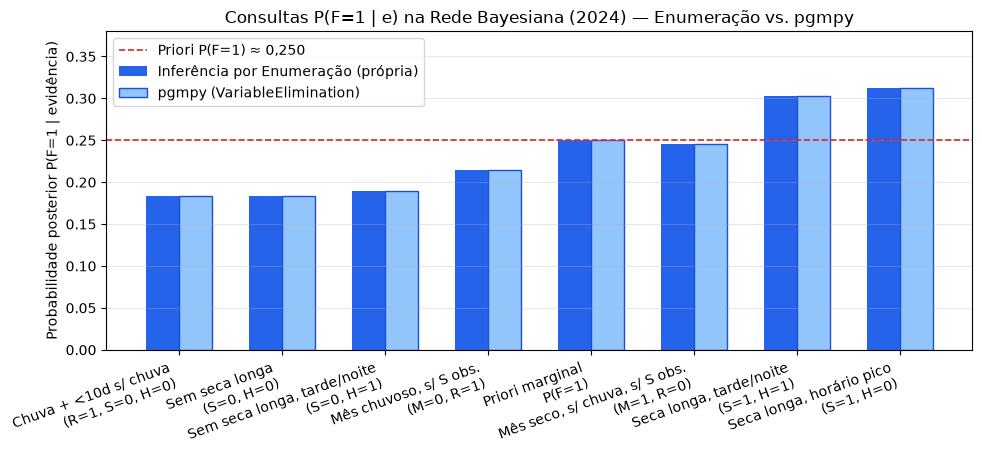

Figura salva em: graficos_etapa5/inferencia_comparacao_pgmpy.png


In [11]:
medianas_2024 = dados_2024[ATRIBUTOS].astype(float).median().to_dict()
q75_2024 = float(dados_2024["frp"].astype(float).quantile(0.75, interpolation="linear"))
X_2024_imp = dados_2024[ATRIBUTOS].astype(float).fillna(medianas_2024)
y_2024_cls = (dados_2024["frp"].astype(float) >= q75_2024).astype(int)

V_2024 = extrair_variaveis_binarias(X_2024_imp, y_2024_cls, medianas_2024)
rede_2024 = RedeBayesianaBinaria().fit(V_2024, alpha=0.0)
ve_2024 = VariableElimination(rede_2024.para_pgmpy())

print(f"Rede ajustada em 2024 completo: N = {rede_2024.n_treino_:,} | Q75 FRP = {q75_2024:.2f} MW")
print("Cortes (2024):", {k: medianas_2024[k] for k in ["mes", "precipitacao", "numero_dias_sem_chuva", "hora_utc"]})

# Tabela de saídas Bayesianas por regime (insumo para a Etapa 6)
saidas_para_etapa6 = []
for s_val, h_val in product((0, 1), repeat=2):
    p_f = rede_2024.inferencia_por_enumeracao("F", {"S": s_val, "H": h_val})[1]
    p_f_pgmpy = ve_2024.query(["F"], evidence={"S": s_val, "H": h_val}, show_progress=False).values[1]
    assert np.isclose(p_f, p_f_pgmpy, atol=1e-12)
    saidas_para_etapa6.append({
        "Cenário (S, H)": f"S={s_val} ({'seca ≥ 10d' if s_val else 'seca < 10d'}), H={h_val} ({'≥ 18,1h' if h_val else '< 18,1h'})",
        "S": s_val,
        "H": h_val,
        "P(F=1 | S, H) [Rede / pgmpy]": p_f,
    })
df_saidas_sh = pd.DataFrame(saidas_para_etapa6)
display(Markdown("#### Probabilidades posteriores $P(F=1 \\mid S, H)$ em 2024 completo (Manto de Markov de $F$)"))
display(df_saidas_sh)

# Gráfico: Probabilidades posteriores da Rede Bayesiana em diferentes cenários de evidência
cenarios_plot = [
    ("Chuva + <10d s/ chuva\n(R=1, S=0, H=0)", {"R": 1, "S": 0, "H": 0}),
    ("Sem seca longa\n(S=0, H=0)", {"S": 0, "H": 0}),
    ("Sem seca longa, tarde/noite\n(S=0, H=1)", {"S": 0, "H": 1}),
    ("Mês chuvoso, s/ S obs.\n(M=0, R=1)", {"M": 0, "R": 1}),
    ("Priori marginal\nP(F=1)", {}),
    ("Mês seco, s/ chuva, s/ S obs.\n(M=1, R=0)", {"M": 1, "R": 0}),
    ("Seca longa, tarde/noite\n(S=1, H=1)", {"S": 1, "H": 1}),
    ("Seca longa, horário pico\n(S=1, H=0)", {"S": 1, "H": 0}),
]

rotulos_c = [c[0] for c in cenarios_plot]
vals_enum = [rede_2024.inferencia_por_enumeracao("F", c[1])[1] for c in cenarios_plot]
vals_pgmpy = [ve_2024.query(["F"], evidence=c[1], show_progress=False).values[1] for c in cenarios_plot]

fig, ax = plt.subplots(figsize=(10, 4.8))
x_pos = np.arange(len(rotulos_c))
ax.bar(x_pos - 0.16, vals_enum, width=0.32, label="Inferência por Enumeração (própria)", color="#2563eb")
ax.bar(x_pos + 0.16, vals_pgmpy, width=0.32, label="pgmpy (VariableElimination)", color="#93c5fd", edgecolor="#1d4ed8")
ax.axhline(rede_2024.inferencia_por_enumeracao("F")[1], color="#dc2626", ls="--", lw=1.2, label="Priori P(F=1) ≈ 0,250")
ax.set_xticks(x_pos, rotulos_c, rotation=20, ha="right")
ax.set_ylabel("Probabilidade posterior P(F=1 | evidência)")
ax.set_ylim(0, 0.38)
ax.set_title("Consultas P(F=1 | e) na Rede Bayesiana (2024) — Enumeração vs. pgmpy")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
caminho_plot_inf = DIRETORIO_GRAFICOS / "inferencia_comparacao_pgmpy.png"
fig.savefig(caminho_plot_inf, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print("Figura salva em:", caminho_plot_inf)

## 8. Discussão, narrativa da etapa e limitações

**O que foi feito e por quê.** Nesta etapa construímos uma Rede Bayesiana acíclica sobre cinco variáveis binárias do domínio ($M, R, S, H, F$) para superar a limitação estrutural do Naive Bayes da Etapa 4. Na Etapa 3 havíamos demonstrado que a época do ano ($M$), a chuva instantânea ($R$) e o período longo sem chuva ($S$) apresentam forte dependência condicional dentro de cada classe ($\phi(S,R\mid F) \approx -0{,}32$), violando a hipótese ingênua de independência. Ao introduzir as arestas $M \to R$, $M \to S$ e $R \to S$, a rede modela explicitamente a cascata meteorológica que leva à estiagem acumulada e condiciona a potência radiativa elevada ($F$) apenas aos seus pais diretos ($S \to F \leftarrow H$). Isso reduz a parametrização de **31 parâmetros livres** na conjunta completa para apenas **12 parâmetros livres** (economia de **19 parâmetros**, ou $61{,}3\%$), enquanto reduz pela metade o erro de reconstrução da distribuição conjunta (Distância de Variação Total média de $0{,}089$ na Rede Bayesiana contra $0{,}176$ no Naive Bayes).

**O que aprendemos com a inferência e a d-separação.** Implementamos o algoritmo `ENUMERATION-ASK` do zero e confirmamos que suas respostas coincidem até a precisão de máquina ($|\Delta| < 10^{-16}$) com o `VariableElimination` do `pgmpy` em todas as consultas causais, diagnósticas e intercausais. Pela análise de d-separação, verificamos duas propriedades estruturais fundamentais: (i) o período longo sem chuva ($S$) atua como mediador que bloqueia o fluxo de informação de $M$ e $R$ para $F$ ($M \perp_d F \mid S$ e $R \perp_d F \mid S$), mas permite inferir o risco de FRP elevada via $P(S\mid M,R)$ sempre que o histórico de dias sem chuva não estiver disponível; e (ii) o nó $F$ atua como um **colisor** ($S \to F \leftarrow H$): enquanto $S$ e $H$ são marginalmente independentes na rede ($P(S=1\mid H=1) = P(S=1\mid H=0) = 0{,}5237$), observar um foco de alta potência ($F=1$) abre o caminho entre suas causas (*explaining away*), elevando a probabilidade posterior de estiagem longa para $0{,}6558$ quando $H=0$ contra $0{,}6342$ quando $H=1$. Nos cinco folds espaciais de 2024, a Rede Bayesiana reproduziu com muito maior fidelidade a distribuição conjunta das variáveis em municípios inéditos e obteve menor Log-Loss médio do que o Bernoulli Naive Bayes.

**Limitações e integração com a Etapa 6.** Assim como nas etapas anteriores, (i) o dataset contém apenas focos já detectados pelo sensor `AQUA_M-T`, de modo que $P(F=1\mid \mathbf{e})$ mede a probabilidade de potência radiativa no quartil superior **dado que houve detecção**, e não o risco de ignição; (ii) a binarização por medianas do treino garante paridade com as Etapas 1, 3 e 4 e simplicidade nas CPTs, mas comprime a relação contínua de `numero_dias_sem_chuva` em dois níveis (o que limita a probabilidade máxima prevista em $\approx 31{,}7\%$, abaixo do limiar rígido de $0{,}5$); e (iii) justamente porque um corte booleano rígido em $0{,}5$ não captura a gradação de risco entre $\approx 18\%$ e $\approx 32\%$, as probabilidades contínuas $P(F=1\mid \mathbf{e})$ produzidas por esta Rede Bayesiana serão combinadas com variáveis linguísticas no sistema de inferência **Fuzzy Mamdani da Etapa 6** para gerar uma decisão operacional suave e interpretável.